## Étape 1 : Importation des bibliothèques et chargement du fichier
On importe les bibliothèques de base vues en classe (`pandas`, `numpy`, `matplotlib`, `seaborn`) ainsi que les outils statistiques pour le Sprint 2.

In [1]:
# 1. Importation des bibliothèques vues en cours
import re
import unicodedata
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu, fisher_exact
from statsmodels.stats.multitest import multipletests

# Style simple pour les graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
# 2. Chargement du jeu de données (adapter le chemin si le fichier est dans data/raw/)
df_brut = pd.read_excel('dataset_covid.xlsx')

# Afficher les 5 premières lignes pour vérifier que le fichier est bien chargé
df_brut.head()

,Patient ID,Patient age quantile,SARS-Cov-2 exam result,"Patient addmited to regular ward (1=yes, 0=no)","Patient addmited to semi-intensive unit (1=yes, 0=no)","Patient addmited to intensive care unit (1=yes, 0=no)",Hematocrit,Hemoglobin,Platelets,Mean platelet volume,...,Hb saturation (arterial blood gases),pCO2 (arterial blood gas analysis),Base excess (arterial blood gas analysis),pH (arterial blood gas analysis),Total CO2 (arterial blood gas analysis),HCO3 (arterial blood gas analysis),pO2 (arterial blood gas analysis),Arteiral Fio2,Phosphor,ctO2 (arterial blood gas analysis)
0,44477f75e8169d2,13,negative,0,0,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,126e9dd13932f68,17,negative,0,0,0,0.236515,-0.02234,-0.517413,0.010677,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,a46b4402a0e5696,8,negative,0,0,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,f7d619a94f97c45,5,negative,0,0,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,d9e41465789c2b5,15,negative,0,0,0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Étape 2 : Exploration générale de la structure des données
On vérifie la taille du tableau (`shape`), les types de colonnes (`dtypes`), les doublons et les statistiques descriptives (`describe`).

In [3]:
# Vérifier les dimensions du jeu de données (lignes, colonnes)
print("Dimensions du tableau (lignes, colonnes) :", df_brut.shape)
print("Nombre de lignes en double :", df_brut.duplicated().sum())

# Voir combien il y a de colonnes numériques (float64, int64) et texte (object)
print("\nTypes de données dans le fichier :")
print(df_brut.dtypes.value_counts())

# Répartition de la variable cible (positifs vs négatifs)
print("\nRépartition du test SARS-Cov-2 :")
print(df_brut['SARS-Cov-2 exam result'].value_counts())

# Résumé statistique des colonnes numériques
df_brut.describe()

Dimensions du tableau (lignes, colonnes) : (5644, 111)
Nombre de lignes en double : 0

Types de données dans le fichier :
float64    70
object     37
int64       4
Name: count, dtype: int64

Répartition du test SARS-Cov-2 :
SARS-Cov-2 exam result
negative    5086
positive     558
Name: count, dtype: int64


,Patient age quantile,"Patient addmited to regular ward (1=yes, 0=no)","Patient addmited to semi-intensive unit (1=yes, 0=no)","Patient addmited to intensive care unit (1=yes, 0=no)",Hematocrit,Hemoglobin,Platelets,Mean platelet volume,Red blood Cells,Lymphocytes,...,Hb saturation (arterial blood gases),pCO2 (arterial blood gas analysis),Base excess (arterial blood gas analysis),pH (arterial blood gas analysis),Total CO2 (arterial blood gas analysis),HCO3 (arterial blood gas analysis),pO2 (arterial blood gas analysis),Arteiral Fio2,Phosphor,ctO2 (arterial blood gas analysis)
count,5644.000000,5644.000000,5644.000000,5644.000000,6.030000e+02,6.030000e+02,6.020000e+02,5.990000e+02,6.020000e+02,6.020000e+02,...,2.700000e+01,2.700000e+01,2.700000e+01,2.700000e+01,2.700000e+01,2.700000e+01,2.700000e+01,2.000000e+01,2.000000e+01,2.700000e+01
mean,9.318391,0.013997,0.008859,0.007264,-2.186214e-09,-1.601319e-08,-3.535004e-10,7.438142e-09,8.424447e-09,-7.866736e-09,...,-1.379737e-10,8.416397e-09,-1.655685e-09,4.139211e-10,-7.472139e-09,6.070843e-09,-2.469729e-08,4.656613e-09,6.332993e-09,5.243001e-09
std,5.777903,0.117489,0.093713,0.084929,1.000830e+00,1.000830e+00,1.000832e+00,1.000836e+00,1.000832e+00,1.000832e+00,...,1.019049e+00,1.019049e+00,1.019049e+00,1.019049e+00,1.019049e+00,1.019049e+00,1.019049e+00,1.025978e+00,1.025978e+00,1.019049e+00
min,0.000000,0.000000,0.000000,0.000000,-4.501420e+00,-4.345603e+00,-2.552426e+00,-2.457575e+00,-3.970608e+00,-1.865070e+00,...,-1.999560e+00,-1.244817e+00,-3.082674e+00,-3.568877e+00,-2.925618e+00,-2.985592e+00,-1.175907e+00,-1.532932e+00,-1.480526e+00,-2.900254e+00
25%,4.000000,0.000000,0.000000,0.000000,-5.188074e-01,-5.862439e-01,-6.053457e-01,-6.624832e-01,-5.679496e-01,-7.307069e-01,...,-1.122574e+00,-5.348102e-01,-3.308668e-01,-9.210583e-02,-5.117720e-01,-5.397211e-01,-8.169898e-01,-1.214975e-01,-5.527296e-01,-4.852787e-01
50%,9.000000,0.000000,0.000000,0.000000,5.340703e-02,4.031596e-02,-1.217160e-01,-1.015171e-01,1.385207e-02,-1.426696e-02,...,2.677689e-01,-2.120799e-01,-1.181667e-02,2.942021e-01,7.743482e-02,5.633191e-02,-1.599549e-01,-1.174366e-02,-1.381825e-01,1.826928e-01
75%,14.000000,0.000000,0.000000,0.000000,7.171751e-01,7.295320e-01,5.314981e-01,6.838353e-01,6.661759e-01,5.976919e-01,...,7.383496e-01,2.305214e-02,6.661649e-01,5.115003e-01,4.385609e-01,5.085100e-01,4.500090e-01,-1.174366e-02,2.763648e-01,5.937525e-01
max,19.000000,1.000000,1.000000,1.000000,2.662704e+00,2.671868e+00,9.532034e+00,3.713052e+00,3.645706e+00,3.764100e+00,...,1.337265e+00,3.236524e+00,1.703078e+00,1.042674e+00,1.940087e+00,2.029471e+00,2.205371e+00,2.841856e+00,2.862350e+00,1.826932e+00


## Étape 3 : Évaluation de la qualité des données et réponse Q7 (Sprint 1)
### 3.1. Vérification des valeurs manquantes (`isnull().sum()`)
On calcule le nombre et le pourcentage de valeurs manquantes (`NaN`) pour chaque colonne.

In [4]:
# Calculer le nombre et le pourcentage de valeurs manquantes par colonne
nb_manquants = df_brut.isnull().sum()
pct_manquants = (nb_manquants / len(df_brut)) * 100

# Tableau récapitulatif
table_manquants = pd.DataFrame({
    'Nombre de NaN': nb_manquants,
    'Pourcentage (%)': pct_manquants.round(2)
})

# Afficher les 20 colonnes qui ont le MOINS de valeurs manquantes
print("Les 20 colonnes les mieux remplies du fichier :")
print(table_manquants.sort_values(by='Pourcentage (%)').head(20))

Les 20 colonnes les mieux remplies du fichier :
                                                    Nombre de NaN  \
Patient ID                                                      0   
Patient age quantile                                            0   
SARS-Cov-2 exam result                                          0   
Patient addmited to regular ward (1=yes, 0=no)                  0   
Patient addmited to semi-intensive unit (1=yes,...              0   
Patient addmited to intensive care unit (1=yes,...              0   
Influenza B                                                  4290   
Respiratory Syncytial Virus                                  4290   
Influenza A                                                  4290   
Rhinovirus/Enterovirus                                       4292   
Inf A H1N1 2009                                              4292   
CoronavirusOC43                                              4292   
Coronavirus229E                                        

### 3.2. Colonnes vides et complétude par groupe d'examens (Q7)
On liste les colonnes 100 % vides à supprimer et on mesure la complétude moyenne par famille d'examens.

Colonnes avec >= 90 % de manquants : 72 sur 111
Colonnes 100 % vides (5) :
 - Mycoplasma pneumoniae
 - Urine - Sugar
 - Partial thromboplastin time (PTT) 
 - Prothrombin time (PT), Activity
 - D-Dimer

Complétude moyenne par groupe d'examens :
                      count  mean
Groupe                           
Urine                    15   1.0
Gaz du sang              18   1.2
Biochimie et autres      35   3.5
Hémogramme               17   9.0
Tests rapides             2  14.5
Panel viral PCR          17  22.6
Identifiant / Cibles      7  85.9


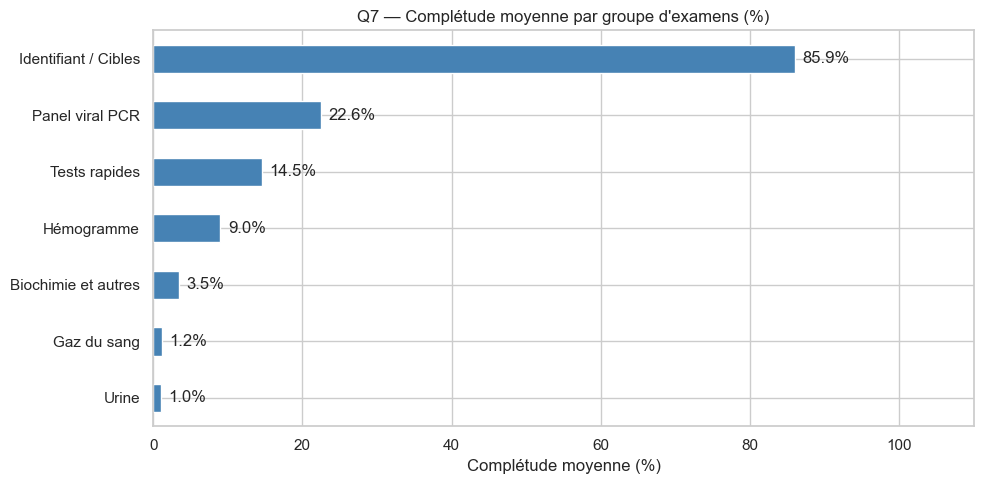

In [5]:
# Repérer les colonnes >= 90 % manquantes et celles 100 % vides
colonnes_vides = table_manquants[table_manquants['Pourcentage (%)'] == 100.0].index.tolist()
nb_plus_90 = (table_manquants['Pourcentage (%)'] >= 90.0).sum()

print(f"Colonnes avec >= 90 % de manquants : {nb_plus_90} sur {df_brut.shape[1]}")
print(f"Colonnes 100 % vides ({len(colonnes_vides)}) :")
for col in colonnes_vides:
    print(" -", col)

# Regroupement simple des colonnes par famille d'examens
def classer_colonne(nom):
    n = str(nom).lower()
    if any(k in n for k in ['patient', 'sars-cov-2']):
        return 'Identifiant / Cibles'
    if any(k in n for k in ['hematocrit', 'hemoglobin', 'platelet', 'red blood', 'lymphocyte', 'leukocyte', 'basophil', 'eosinophil', 'monocyte', 'mch', 'mcv', 'rdw', 'mpv']):
        return 'Hémogramme'
    if 'rapid test' in n:
        return 'Tests rapides'
    if any(k in n for k in ['virus', 'influenza', 'parainfluenza', 'coronavirus', 'bordetella', 'chlamydophila', 'mycoplasma', 'metapneumovirus']):
        return 'Panel viral PCR'
    if 'urine' in n:
        return 'Urine'
    if any(k in n for k in ['venous', 'arterial', 'arteiral']):
        return 'Gaz du sang'
    return 'Biochimie et autres'

df_q7 = pd.DataFrame({
    'Colonne': df_brut.columns,
    'Groupe': [classer_colonne(c) for c in df_brut.columns],
    'Completude (%)': 100 - pct_manquants.values
})

resume_q7 = df_q7.groupby('Groupe')['Completude (%)'].agg(['count', 'mean']).sort_values('mean', ascending=True)
print("\nComplétude moyenne par groupe d'examens :")
print(resume_q7.round(1))

# Graphique Q7
ax = resume_q7['mean'].plot(kind='barh', color='steelblue')
ax.set_title("Q7 — Complétude moyenne par groupe d'examens (%)")
ax.set_xlabel("Complétude moyenne (%)")
ax.set_ylabel("")
for i, v in enumerate(resume_q7['mean']):
    ax.text(v + 1, i, f"{v:.1f}%", va='center')
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

## Étape 4 : Nettoyage, normalisation et variables dérivées (Sprint 1)
On retire les colonnes vides, on nettoie les noms en `snake_case`, on corrige `urine_ph`, on encode les variables binaires et on crée les variables communes.

In [6]:
# Copie de travail sans les colonnes 100 % vides
df = df_brut.drop(columns=colonnes_vides).copy()

# Normaliser les noms de colonnes (corrigé + snake_case sans accents)
def nettoyer_nom(col):
    col = str(col).replace("\xa0", " ").strip()
    col = col.replace("addmited", "admitted").replace("Arteiral", "Arterial")
    col = unicodedata.normalize("NFKD", col).encode("ascii", "ignore").decode("ascii")
    col = re.sub(r"[^a-zA-Z0-9]+", "_", col.lower()).strip("_")
    return col

df.columns = [nettoyer_nom(c) for c in df.columns]

# Corriger Urine - pH (texte -> numérique)
if 'urine_ph' in df.columns:
    df['urine_ph'] = pd.to_numeric(df['urine_ph'], errors='coerce')

# Encodage binaire (positive/negative et detected/not_detected -> 1/0) en gardant les NaN
mapping_binaire = {
    'positive': 1, 'negative': 0,
    'detected': 1, 'not_detected': 0
}

for col in df.select_dtypes(include=['object', 'string']).columns:
    valeurs = set(df[col].dropna().astype(str).str.strip().str.lower().unique())
    if valeurs and valeurs.issubset(mapping_binaire.keys()):
        df[col] = df[col].astype(str).str.strip().str.lower().map(mapping_binaire)

print(f"Nettoyage terminé : {df.shape[0]} lignes x {df.shape[1]} colonnes")

Nettoyage terminé : 5644 lignes x 106 colonnes


In [ ]:
# Variables dérivées communes
# 1. Variable cible principale (0 = négatif, 1 = positif)
df['covid_positif'] = df['sars_cov_2_exam_result'].astype(int)

# 2. Niveau d'admission : 0=Aucune, 1=Unité régulière, 2=Semi-intensif, 3=Soins intensifs
col_reg = 'patient_admitted_to_regular_ward_1_yes_0_no'
col_semi = 'patient_admitted_to_semi_intensive_unit_1_yes_0_no'
col_icu = 'patient_admitted_to#_intensive_care_unit_1_yes_0_no'

df['niveau_admission'] = 0
df.loc[df[col_reg] == 1, 'niveau_admission'] = 1
df.loc[df[col_semi] == 1, 'niveau_admission'] = 2
df.loc[df[col_icu] == 1, 'niveau_admission'] = 3

# 3. Indicateurs de disponibilité des examens
cols_hemogramme = [
    c for c in [
        'hematocrit', 'hemoglobin', 'platelets', 'leukocytes',
        'lymphocytes', 'monocytes', 'eosinophils', 'basophils',
        'red_blood_cells', 'mean_platelet_volume', 'mean_corpuscular_volume_mcv',
        'mean_corpuscular_hemoglobin_mch', 'mean_corpuscular_hemoglobin_concentration_mchc',
        'red_blood_cell_distribution_width_rdw'
    ] if c in df.columns
]
df['has_blood_count'] = df[cols_hemogramme].notna().any(axis=1).astype(int)

cols_panel_viral = [
    c for c in df.columns
    if any(k in c for k in [
        'respiratory_syncytial', 'influenza', 'parainfluenza', 'coronavirus',
        'rhinovirus', 'enterovirus', 'metapneumovirus', 'adenovirus',
        'bordetella', 'chlamydophila'
    ]) and 'rapid_test' not in c
]
df['has_viral_panel'] = df[cols_panel_viral].notna().any(axis=1).astype(int)

print("Variables dérivées créées : covid_positif, niveau_admission, has_blood_count, has_viral_panel")

## Étape 5 : Création des sous-jeux d'analyse et sauvegarde (Sprint 1)
On crée les sous-jeux standardisés (`hémogramme`, `positifs`, `panel viral`) et on vérifie les effectifs.

In [ ]:
df_hemogramme = df[df['has_blood_count'] == 1].copy()
df_positifs = df[df['covid_positif'] == 1].copy()
df_panel_viral = df[df['has_viral_panel'] == 1].copy()

print(f"Dataset complet   : {len(df)} patients ({df['covid_positif'].sum()} positifs)")
print(f"Sous-jeu hémogr.  : {len(df_hemogramme)} patients ({df_hemogramme['covid_positif'].sum()} positifs)")
print(f"Sous-jeu positifs : {len(df_positifs)} patients")
print(f"Sous-jeu viral    : {len(df_panel_viral)} patients ({len(df_panel_viral)/len(df)*100:.1f} %)")

# Sauvegarde locale (dossier ignoré par .gitignore)
dossier_sortie = Path('data/processed')
dossier_sortie.mkdir(parents=True, exist_ok=True)

df.to_csv(dossier_sortie / 'dataset_propre.csv', index=False)
df_hemogramme.to_csv(dossier_sortie / 'sous_jeu_hemogramme.csv', index=False)
df_positifs.to_csv(dossier_sortie / 'sous_jeu_positifs.csv', index=False)
df_panel_viral.to_csv(dossier_sortie / 'sous_jeu_panel_viral.csv', index=False)
print("Fichiers CSV enregistrés dans data/processed/")

---
## Étape 6 : Sprint 2 — Q1 & Q2 (Positivité globale et par quantile d'âge)
On calcule le taux de positivité global et on teste l'association avec les quantiles d'âge (test du $\chi^2$).

In [ ]:
# Q1 : Taux de positivité global et déséquilibre
nb_total = len(df)
nb_pos = df['covid_positif'].sum()
taux_global = nb_pos / nb_total * 100

print(f"Q1 — Positifs : {nb_pos} / {nb_total} ({taux_global:.2f} %)")
print(f"Exactitude d'un modèle naïf ('toujours négatif') : {100 - taux_global:.2f} %")

# Q2 : Tableau croisé âge x résultat + test du khi-deux
table_age = pd.crosstab(df['patient_age_quantile'], df['covid_positif'])
chi2, p_val, ddl, _ = chi2_contingency(table_age)
print(f"\nQ2 — Test du khi-deux : chi2 = {chi2:.2f}, ddl = {ddl}, p-valeur = {p_val:.4e}")

# Taux et effectifs par quantile d'âge
stats_age = df.groupby('patient_age_quantile')['covid_positif'].agg(effectif='count', positifs='sum')
stats_age['taux_positivite (%)'] = stats_age['positifs'] / stats_age['effectif'] * 100

# Graphique en barres
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(stats_age.index.astype(str), stats_age['taux_positivite (%)'], color='coral')
ax.axhline(taux_global, color='black', linestyle='--', label=f"Moyenne globale ({taux_global:.1f}%)")
ax.set_title("Q1-Q2 — Taux de positivité SARS-CoV-2 par quantile d'âge")
ax.set_xlabel("Quantile d'âge (0 = plus jeune, 19 = plus âgé)")
ax.set_ylabel("Taux de positivité (%)")
ax.legend()

for bar, n in zip(bars, stats_age['effectif']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4, f"n={n}", ha='center', fontsize=8)

plt.tight_layout()
plt.show()